In [4]:
import pandas as pd
import numpy as np
import sqlite3
from scipy import stats

print("PesaPap Growth Analytics")
print("Libraries imported successfully!")

PesaPap Growth Analytics
Libraries imported successfully!


In [5]:
import pandas as pd

users = pd.read_csv("users.csv")
transactions = pd.read_csv("transactions.csv")
experiment = pd.read_csv("experiment.csv")

print("Users:", users.shape)
print("Transactions:", transactions.shape)
print("Experiment:", experiment.shape)

Users: (3000, 4)
Transactions: (12000, 5)
Experiment: (3000, 3)


In [6]:
from google.colab import files
files.download("users.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files
files.download("transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from google.colab import files
files.download("experiment.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import zipfile

with zipfile.ZipFile("pesapap_datasets.zip", "r") as z:
    z.extractall(".")

print("Datasets extracted successfully!")

Datasets extracted successfully!


In [10]:
import pandas as pd

users = pd.read_csv("users.csv")
transactions = pd.read_csv("transactions.csv")
experiment = pd.read_csv("experiment.csv")

print("Users:", users.shape)
print("Transactions:", transactions.shape)
print("Experiment:", experiment.shape)

Users: (3000, 4)
Transactions: (12000, 5)
Experiment: (3000, 3)


In [11]:
import sqlite3

# Create the SQLite database
conn = sqlite3.connect("pesapap.db")

# Save each dataset as a database table
users.to_sql("users", conn, if_exists="replace", index=False)
transactions.to_sql("transactions", conn, if_exists="replace", index=False)
experiment.to_sql("experiment", conn, if_exists="replace", index=False)

print("Database created successfully!")
print("Tables: users, transactions, experiment")

Database created successfully!
Tables: users, transactions, experiment


In [12]:
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
""")

print("Database tables:")
for table in cursor.fetchall():
    print(table[0])

Database tables:
experiment
transactions
users


In [13]:
query_a = """
SELECT
    product,
    SUM(amount) AS total_transaction_value,
    COUNT(*) AS transaction_count
FROM transactions
GROUP BY product
ORDER BY total_transaction_value DESC;
"""

result_a = pd.read_sql(query_a, conn)
display(result_a)

,product,total_transaction_value,transaction_count
0,Send Money,5639308.0,4161
1,Airtime,4708104.0,3662
2,Bill Pay,3224392.0,2388
3,Merchant Pay,2407505.0,1789


In [14]:
query_b = """
SELECT
    u.county,
    SUM(t.amount) AS total_transaction_value
FROM transactions AS t
JOIN users AS u
    ON t.user_id = u.user_id
GROUP BY u.county
ORDER BY total_transaction_value DESC
LIMIT 5;
"""

result_b = pd.read_sql(query_b, conn)
display(result_b)

,county,total_transaction_value
0,Mombasa,3464271.0
1,Nairobi,3403364.0
2,Nakuru,3138079.0
3,Kisumu,3059055.0
4,Eldoret,2914540.0


In [15]:
query_c = """
WITH monthly_sales AS (
    SELECT
        strftime('%Y-%m', txn_date) AS month,
        SUM(amount) AS monthly_transaction_value
    FROM transactions
    GROUP BY strftime('%Y-%m', txn_date)
)
SELECT
    month,
    monthly_transaction_value,
    SUM(monthly_transaction_value) OVER (
        ORDER BY month
    ) AS running_total
FROM monthly_sales
ORDER BY month;
"""

result_c = pd.read_sql(query_c, conn)
display(result_c)

,month,monthly_transaction_value,running_total
0,2026-01,1733121.0,1733121.0
1,2026-02,2993105.0,4726226.0
2,2026-03,3199125.0,7925351.0
3,2026-04,3262447.0,11187798.0
4,2026-05,3365002.0,14552800.0
5,2026-06,1426509.0,15979309.0


In [16]:
query_d = """
SELECT
    u.acquisition_channel,
    SUM(t.amount) AS total_transaction_value,
    COUNT(t.txn_id) AS transaction_count
FROM users AS u
JOIN transactions AS t
    ON u.user_id = t.user_id
GROUP BY u.acquisition_channel
ORDER BY total_transaction_value DESC;
"""

result_d = pd.read_sql(query_d, conn)
display(result_d)

,acquisition_channel,total_transaction_value,transaction_count
0,Search,4279089.0,3192
1,Agent,3954250.0,2919
2,Social,3926296.0,3008
3,Referral,3819674.0,2881


In [17]:
query_e = """
SELECT
    t.user_id,
    SUM(t.amount) AS total_transaction_value,
    RANK() OVER (
        ORDER BY SUM(t.amount) DESC
    ) AS user_rank
FROM transactions AS t
GROUP BY t.user_id
ORDER BY user_rank
LIMIT 10;
"""

result_e = pd.read_sql(query_e, conn)
display(result_e)

,user_id,total_transaction_value,user_rank
0,1962,29244.0,1
1,2643,29144.0,2
2,2894,28008.0,3
3,2671,27317.0,4
4,50,27158.0,5
5,2279,26634.0,6
6,2837,25643.0,7
7,514,24747.0,8
8,670,23041.0,9
9,2681,22850.0,10


In [18]:
query_f = """
SELECT
    product,
    AVG(amount) AS average_transaction_value,
    COUNT(*) AS transaction_count
FROM transactions
GROUP BY product
HAVING AVG(amount) > 1300
ORDER BY average_transaction_value DESC;
"""

result_f = pd.read_sql(query_f, conn)
display(result_f)

,product,average_transaction_value,transaction_count
0,Send Money,1355.277097,4161
1,Bill Pay,1350.247906,2388
2,Merchant Pay,1345.726663,1789


In [19]:
query_g = """
WITH user_values AS (
    SELECT
        user_id,
        SUM(amount) AS total_value
    FROM transactions
    GROUP BY user_id
),
user_tiers AS (
    SELECT
        user_id,
        CASE
            WHEN total_value >= 10000 THEN 'High'
            WHEN total_value >= 4000 THEN 'Medium'
            ELSE 'Low'
        END AS value_tier
    FROM user_values
)
SELECT
    value_tier,
    COUNT(*) AS user_count
FROM user_tiers
GROUP BY value_tier
ORDER BY
    CASE value_tier
        WHEN 'High' THEN 1
        WHEN 'Medium' THEN 2
        WHEN 'Low' THEN 3
    END;
"""

result_g = pd.read_sql(query_g, conn)
display(result_g)

,value_tier,user_count
0,High,345
1,Medium,1317
2,Low,1281


In [20]:
query_h = """
WITH monthly_active_users AS (
    SELECT
        strftime('%Y-%m', txn_date) AS month,
        COUNT(DISTINCT user_id) AS active_users
    FROM transactions
    GROUP BY strftime('%Y-%m', txn_date)
),
monthly_comparison AS (
    SELECT
        month,
        active_users,
        LAG(active_users) OVER (
            ORDER BY month
        ) AS previous_month_active_users
    FROM monthly_active_users
)
SELECT
    month,
    active_users,
    previous_month_active_users,
    active_users - previous_month_active_users AS change_in_active_users,
    CASE
        WHEN previous_month_active_users IS NULL THEN 'No previous month'
        WHEN active_users > previous_month_active_users THEN 'Increased'
        WHEN active_users < previous_month_active_users THEN 'Decreased'
        ELSE 'No change'
    END AS month_over_month_status
FROM monthly_comparison
ORDER BY month;
"""

result_h = pd.read_sql(query_h, conn)
display(result_h)

,month,active_users,previous_month_active_users,change_in_active_users,month_over_month_status
0,2026-01,1055,NaN,NaN,No previous month
1,2026-02,1596,1055.0,541.0,Increased
2,2026-03,1649,1596.0,53.0,Increased
3,2026-04,1704,1649.0,55.0,Increased
4,2026-05,1690,1704.0,-14.0,Decreased
5,2026-06,907,1690.0,-783.0,Decreased


In [21]:
query_validation = """
SELECT
    COUNT(*) AS invalid_transaction_count
FROM transactions AS t
JOIN users AS u
    ON t.user_id = u.user_id
WHERE DATE(t.txn_date) < DATE(u.signup_date);
"""

validation_result = pd.read_sql(query_validation, conn)
display(validation_result)

,invalid_transaction_count
0,3737


In [22]:
# Calculate key business performance indicators

total_value = transactions["amount"].sum()
transaction_count = transactions["txn_id"].nunique()
active_users = transactions["user_id"].nunique()
average_transaction_value = transactions["amount"].mean()
average_transactions_per_user = transaction_count / active_users

kpi_scorecard = pd.DataFrame({
    "Metric": [
        "Total Transaction Value (KES)",
        "Transaction Count",
        "Active Users",
        "Average Transaction Value (KES)",
        "Average Transactions per Active User"
    ],
    "Value": [
        total_value,
        transaction_count,
        active_users,
        average_transaction_value,
        average_transactions_per_user
    ],
    "Definition": [
        "Sum of all transaction amounts",
        "Number of unique transactions",
        "Unique users who made at least one transaction",
        "Total transaction value divided by transaction count",
        "Transaction count divided by active users"
    ]
})

display(kpi_scorecard.round(2))

,Metric,Value,Definition
0,Total Transaction Value (KES),15979309.00,Sum of all transaction amounts
1,Transaction Count,12000.00,Number of unique transactions
2,Active Users,2943.00,Unique users who made at least one transaction
3,Average Transaction Value (KES),1331.61,Total transaction value divided by transaction...
4,Average Transactions per Active User,4.08,Transaction count divided by active users


In [23]:
# Calculate monthly transaction value and growth

monthly_kpis = (
    transactions.assign(
        month=pd.to_datetime(transactions["txn_date"]).dt.to_period("M")
    )
    .groupby("month")
    .agg(
        monthly_transaction_value=("amount", "sum"),
        monthly_transactions=("txn_id", "nunique"),
        monthly_active_users=("user_id", "nunique")
    )
    .reset_index()
)

monthly_kpis["previous_month_value"] = (
    monthly_kpis["monthly_transaction_value"].shift(1)
)

monthly_kpis["mom_growth_percent"] = (
    (
        monthly_kpis["monthly_transaction_value"]
        - monthly_kpis["previous_month_value"]
    )
    / monthly_kpis["previous_month_value"]
    * 100
)

display(monthly_kpis.round(2))

,month,monthly_transaction_value,monthly_transactions,monthly_active_users,previous_month_value,mom_growth_percent
0,2026-01,1733121.0,1308,1055,NaN,NaN
1,2026-02,2993105.0,2272,1596,1733121.0,72.70
2,2026-03,3199125.0,2394,1649,2993105.0,6.88
3,2026-04,3262447.0,2470,1704,3199125.0,1.98
4,2026-05,3365002.0,2475,1690,3262447.0,3.14
5,2026-06,1426509.0,1081,907,3365002.0,-57.61


In [24]:
# RFM customer analysis

transactions["txn_date"] = pd.to_datetime(transactions["txn_date"])

analysis_date = transactions["txn_date"].max() + pd.Timedelta(days=1)

rfm = transactions.groupby("user_id").agg(
    recency=("txn_date", lambda x: (analysis_date - x.max()).days),
    frequency=("txn_id", "nunique"),
    monetary=("amount", "sum")
).reset_index()

# Assign scores from 1 to 4
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

def assign_segment(row):
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "High Value"
    elif row["F_score"] >= 3:
        return "Frequent Users"
    elif row["R_score"] <= 2:
        return "At Risk"
    else:
        return "Other Users"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

display(rfm.head(10))
print("\nCustomer segment counts:")
display(rfm["segment"].value_counts().rename_axis("segment").reset_index(name="user_count"))

,user_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
0,1,18,3,2418.0,3,1,1,311,Other Users
1,2,2,6,3316.0,4,4,2,442,Frequent Users
2,3,25,5,3585.0,3,3,2,332,Frequent Users
3,4,15,8,9268.0,3,4,4,344,High Value
4,5,26,2,1945.0,2,1,1,211,At Risk
5,6,89,3,1520.0,1,1,1,111,At Risk
6,7,37,4,6122.0,2,2,3,223,At Risk
7,8,2,10,12009.0,4,4,4,444,High Value
8,9,27,5,3067.0,2,3,2,232,Frequent Users
9,10,48,2,1343.0,2,1,1,211,At Risk



Customer segment counts:


,segment,user_count
0,At Risk,918
1,Frequent Users,755
2,High Value,716
3,Other Users,554


In [25]:
# Monthly customer cohort retention analysis

cohort_data = transactions[["user_id", "txn_date"]].copy()
cohort_data["txn_date"] = pd.to_datetime(cohort_data["txn_date"])

# Find each user's first transaction month
cohort_data["transaction_month"] = (
    cohort_data["txn_date"].dt.to_period("M")
)

cohort_data["cohort_month"] = (
    cohort_data.groupby("user_id")["transaction_month"]
    .transform("min")
)

# Calculate the number of months since joining the cohort
cohort_data["cohort_age"] = (
    (cohort_data["transaction_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    + cohort_data["transaction_month"].dt.month
    - cohort_data["cohort_month"].dt.month
)

# Count distinct active users in each cohort and month
cohort_counts = cohort_data.groupby(
    ["cohort_month", "cohort_age"]
)["user_id"].nunique().reset_index(name="active_users")

cohort_pivot = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_age",
    values="active_users"
)

# Calculate retention percentages
cohort_sizes = cohort_pivot[0]
retention = cohort_pivot.div(cohort_sizes, axis=0) * 100

# Flag incomplete cohort cells: later months have not yet occurred
latest_month = cohort_data["transaction_month"].max()

for cohort_month in retention.index:
    for age in retention.columns:
        observed_month = cohort_month + int(age)
        if observed_month > latest_month:
            retention.loc[cohort_month, age] = np.nan

print("Cohort active-user counts:")
display(cohort_pivot)

print("Cohort retention (%); blank cells are incomplete future periods:")
display(retention.round(1))

Cohort active-user counts:


cohort_age,0,1,2,3,4,5
cohort_month,,,,,,
2026-01,1055.0,555.0,582.0,591.0,600.0,298.0
2026-02,1041.0,568.0,602.0,579.0,318.0,NaN
2026-03,499.0,287.0,287.0,160.0,NaN,NaN
2026-04,224.0,123.0,68.0,NaN,NaN,NaN
2026-05,101.0,40.0,NaN,NaN,NaN,NaN
2026-06,23.0,NaN,NaN,NaN,NaN,NaN


Cohort retention (%); blank cells are incomplete future periods:


cohort_age,0,1,2,3,4,5
cohort_month,,,,,,
2026-01,100.0,52.6,55.2,56.0,56.9,28.2
2026-02,100.0,54.6,57.8,55.6,30.5,NaN
2026-03,100.0,57.5,57.5,32.1,NaN,NaN
2026-04,100.0,54.9,30.4,NaN,NaN,NaN
2026-05,100.0,39.6,NaN,NaN,NaN,NaN
2026-06,100.0,NaN,NaN,NaN,NaN,NaN


In [26]:
# A/B experiment: Define hypotheses and compare group balance

# H0: Groups A and B have the same conversion rate.
# H1: Groups A and B have different conversion rates.

group_balance = experiment.groupby("group").agg(
    users=("user_id", "nunique"),
    conversions=("converted", "sum")
).reset_index()

group_balance["conversion_rate_percent"] = (
    group_balance["conversions"] / group_balance["users"] * 100
)

display(group_balance.round(2))

,group,users,conversions,conversion_rate_percent
0,A,1443,151,10.46
1,B,1557,215,13.81


In [27]:
# A/B test: conversion lift, chi-square test, and 95% confidence interval

from scipy.stats import chi2_contingency, norm
import numpy as np

summary = experiment.groupby("group")["converted"].agg(
    conversions="sum",
    users="count"
)

a_conversions = summary.loc["A", "conversions"]
a_users = summary.loc["A", "users"]
b_conversions = summary.loc["B", "conversions"]
b_users = summary.loc["B", "users"]

rate_a = a_conversions / a_users
rate_b = b_conversions / b_users

absolute_lift_pp = (rate_b - rate_a) * 100
relative_lift_pct = ((rate_b - rate_a) / rate_a) * 100

# Chi-square test
contingency_table = np.array([
    [a_conversions, a_users - a_conversions],
    [b_conversions, b_users - b_conversions]
])

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table, correction=False
)

# 95% confidence interval for the difference in conversion rates (B - A)
se = np.sqrt(
    rate_a * (1 - rate_a) / a_users
    + rate_b * (1 - rate_b) / b_users
)

ci_lower = (rate_b - rate_a) - 1.96 * se
ci_upper = (rate_b - rate_a) + 1.96 * se

print(f"Group A conversion rate: {rate_a:.2%}")
print(f"Group B conversion rate: {rate_b:.2%}")
print(f"Absolute lift: {absolute_lift_pp:.2f} percentage points")
print(f"Relative lift: {relative_lift_pct:.2f}%")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(
    "95% CI for conversion-rate difference (B - A): "
    f"{ci_lower:.2%} to {ci_upper:.2%}"
)

if p_value < 0.05:
    print("Interpretation: The difference is statistically significant at the 5% level.")
else:
    print("Interpretation: The difference is not statistically significant at the 5% level.")

Group A conversion rate: 10.46%
Group B conversion rate: 13.81%
Absolute lift: 3.34 percentage points
Relative lift: 31.96%
Chi-square statistic: 7.8197
P-value: 0.0052
95% CI for conversion-rate difference (B - A): 1.01% to 5.67%
Interpretation: The difference is statistically significant at the 5% level.


In [28]:
# Estimate potential monthly business impact

assumed_monthly_users = 1000

expected_conversions_a = assumed_monthly_users * rate_a
expected_conversions_b = assumed_monthly_users * rate_b

additional_conversions = (
    expected_conversions_b - expected_conversions_a
)

print(f"Assumed monthly users: {assumed_monthly_users:,}")
print(f"Expected conversions using Group A: {expected_conversions_a:.1f}")
print(f"Expected conversions using Group B: {expected_conversions_b:.1f}")
print(f"Estimated additional conversions: {additional_conversions:.1f}")

if p_value < 0.05 and rate_b > rate_a:
    print("Recommendation: Consider a controlled rollout of Group B.")
elif rate_b > rate_a:
    print("Recommendation: Gather more evidence before adopting Group B.")
else:
    print("Recommendation: Do not adopt Group B based on conversion rate alone.")

Assumed monthly users: 1,000
Expected conversions using Group A: 104.6
Expected conversions using Group B: 138.1
Estimated additional conversions: 33.4
Recommendation: Consider a controlled rollout of Group B.


In [29]:
# KPI metric dictionary

metric_dictionary = pd.DataFrame({
    "Metric": [
        "Total Transaction Value",
        "Transaction Count",
        "Active Users",
        "Average Transaction Value",
        "Average Transactions per Active User",
        "Month-over-Month Growth"
    ],
    "Definition": [
        "Total value of all recorded transactions",
        "Number of unique transactions",
        "Number of unique users who made transactions",
        "Total transaction value divided by transaction count",
        "Transaction count divided by active users",
        "Percentage change in transaction value from the previous month"
    ],
    "Calculation": [
        "SUM(amount)",
        "COUNT(DISTINCT txn_id)",
        "COUNT(DISTINCT user_id)",
        "Total value / transaction count",
        "Transaction count / active users",
        "(Current month value - previous month value) / previous month value * 100"
    ]
})

display(metric_dictionary)

,Metric,Definition,Calculation
0,Total Transaction Value,Total value of all recorded transactions,SUM(amount)
1,Transaction Count,Number of unique transactions,COUNT(DISTINCT txn_id)
2,Active Users,Number of unique users who made transactions,COUNT(DISTINCT user_id)
3,Average Transaction Value,Total transaction value divided by transaction...,Total value / transaction count
4,Average Transactions per Active User,Transaction count divided by active users,Transaction count / active users
5,Month-over-Month Growth,Percentage change in transaction value from th...,(Current month value - previous month value) /...


In [30]:
import pandas as pd
import numpy as np

users = pd.read_csv("users.csv")
transactions = pd.read_csv("transactions.csv")
experiment = pd.read_csv("experiment.csv")

print("Datasets loaded successfully!")
print("Users:", users.shape)
print("Transactions:", transactions.shape)
print("Experiment:", experiment.shape)

Datasets loaded successfully!
Users: (3000, 4)
Transactions: (12000, 5)
Experiment: (3000, 3)


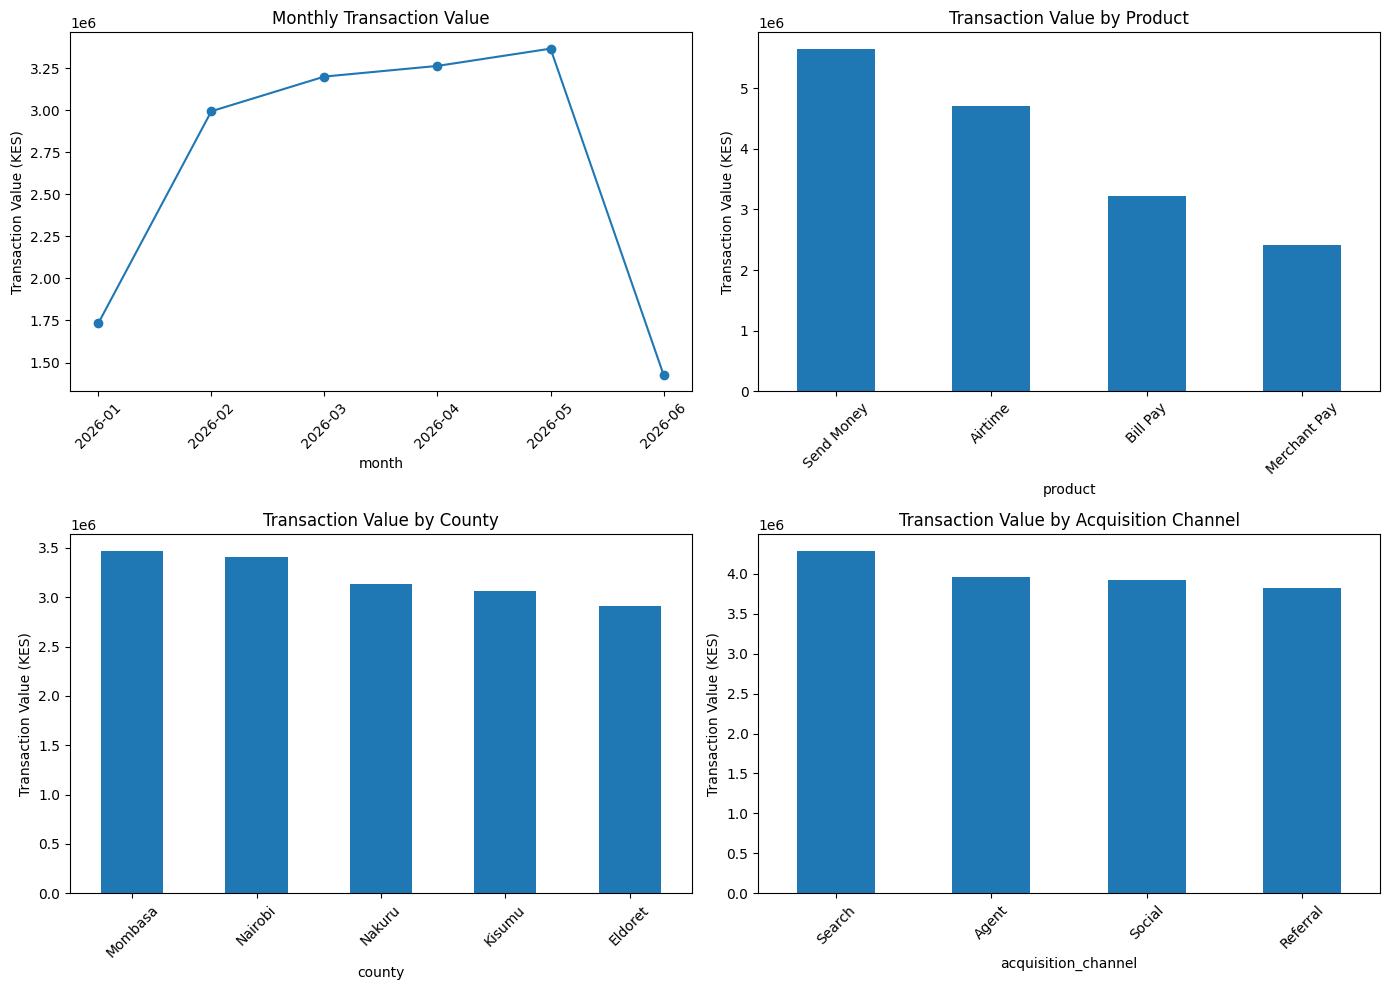

Chart image saved successfully!


In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Create the reports folder
os.makedirs("reports", exist_ok=True)

# Prepare transaction dates
transactions["txn_date"] = pd.to_datetime(transactions["txn_date"])
transactions["month"] = transactions["txn_date"].dt.to_period("M").astype(str)

# Calculate monthly transaction value
monthly_sales = transactions.groupby("month")["amount"].sum()

# Calculate value by product
product_sales = transactions.groupby("product")["amount"].sum().sort_values(ascending=False)

# Calculate value by county
county_sales = (
    transactions.merge(users[["user_id", "county"]], on="user_id")
    .groupby("county")["amount"].sum()
    .sort_values(ascending=False)
)

# Calculate value by acquisition channel
channel_sales = (
    transactions.merge(users[["user_id", "acquisition_channel"]], on="user_id")
    .groupby("acquisition_channel")["amount"].sum()
    .sort_values(ascending=False)
)

# Create four charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

monthly_sales.plot(kind="line", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Monthly Transaction Value")
axes[0, 0].set_ylabel("Transaction Value (KES)")
axes[0, 0].tick_params(axis="x", rotation=45)

product_sales.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Transaction Value by Product")
axes[0, 1].set_ylabel("Transaction Value (KES)")
axes[0, 1].tick_params(axis="x", rotation=45)

county_sales.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Transaction Value by County")
axes[1, 0].set_ylabel("Transaction Value (KES)")
axes[1, 0].tick_params(axis="x", rotation=45)

channel_sales.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Transaction Value by Acquisition Channel")
axes[1, 1].set_ylabel("Transaction Value (KES)")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()

# Save the charts as an image
plt.savefig("reports/growth_charts.png", dpi=200, bbox_inches="tight")
plt.show()

print("Chart image saved successfully!")

In [32]:
from matplotlib.backends.backend_pdf import PdfPages

# Create a PDF report containing the charts
with PdfPages("reports/growth_report.pdf") as pdf:
    pdf.savefig(fig, bbox_inches="tight")

print("PDF report saved successfully!")

PDF report saved successfully!


In [33]:
from google.colab import files

files.download("reports/growth_charts.png")
files.download("reports/growth_report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>